# 01 — Ridge regression: HRI(t+1)

All preprocessing, model parameters, CV, training, metrics and export code is shown in this notebook. Run all cells in order. By default the saved model is loaded and its validation reports are displayed. To develop another model version, choose a new `EXPERIMENT_NAME` and enable `RUN_TRAINING`.

Training uses 2015–2019 targets; validation uses 2020–2021 and/or separate 25 km blocks. The completed v2 test remains frozen. This notebook does not evaluate test targets. HRI is a constructed, partly predictable index; compare against persistence and known-component transitions.

## 1 — Paths, target, weights, and predictor allowlist

In [1]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = globals().get('ROOT')
if ROOT is None:
    ROOT = next((p for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 for p in [base, base / 'components/habitat_risk']
                 if (p / 'configs/hri.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter inside the project repository.')
NOTEBOOK_DIR = ROOT / 'notebooks/hri/HRI_t_plus_1'
# A completed experiment is frozen. Use a new name for further development.
DATA_VERSION = 'hri_t_plus_1_v2'
EXPERIMENT_NAME = 'hri_t_plus_1_v2'

DATA = ROOT / "data/processed/hri" / DATA_VERSION
ARTIFACTS = ROOT / "artifacts/hri" / EXPERIMENT_NAME
KEY = ["cell_id", "reference_year"]
CORE = ["forest_amount_risk", "recent_loss_risk", "cumulative_loss_risk", "fragmentation_risk"]
CONFIG = json.loads((ROOT / "configs/hri.json").read_text())
WEIGHTS = CONFIG["weights"]
THRESHOLDS = CONFIG["risk_class_thresholds"]
RAW_FEATURES = [
    "forest__remaining_baseline_forest_proportion", "forest__annual_loss_fraction_of_baseline",
    "forest__cumulative_prior_loss_fraction_of_baseline", "forest__previous_3yr_loss_fraction_of_baseline",
    "forest__previous_5yr_loss_fraction_of_baseline", "forest__baseline_canopy_percent",
    "fragmentation__cell_patch_count", "fragmentation__mean_cell_patch_ha",
    "fragmentation__edge_m_per_land_ha", "terrain__mean_elevation_m",
    "terrain__mean_slope_degrees", "climate__annual_mean_temperature_c",
    "climate__annual_precipitation_mm",
]
FEATURES = RAW_FEATURES + CORE + [
    "hri_score_t", "hri_change_previous_year", "annual_loss_fraction_lag1",
    "annual_loss_fraction_lag2", "forest_proportion_change_previous_year",
    "edge_density_change_previous_year", "known_recent_loss_risk_t1",
    "known_cumulative_loss_risk_t1", "transition_hri_baseline",
]
TARGET = "target_hri_score_t1"




def risk_class(scores):
    return pd.cut(pd.Series(scores), [-np.inf, THRESHOLDS["low_upper"], THRESHOLDS["moderate_upper"], np.inf],
                  labels=["Low", "Moderate", "High"], right=True).astype("string")

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


In [2]:
import sys
import types
import time
import warnings
import joblib
import sklearn
from IPython.display import display, Image, Markdown
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    balanced_accuracy_score, f1_score, classification_report, confusion_matrix)
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
LABELS = ['Low', 'Moderate', 'High']
MODELS = ['ridge', 'random_forest', 'xgboost']


## 2 — Forecast estimators: direct scores or corrections to a known baseline

In [3]:
class HriForecaster(RegressorMixin, BaseEstimator):
    """A fold-fitted estimator of score or residual relative to an as-of-t baseline."""
    def __init__(self, estimator=None, mode="transition"):
        self.estimator = estimator
        self.mode = mode

    def offset(self, X):
        if self.mode == "direct":
            return np.zeros(len(X))
        return X["hri_score_t" if self.mode == "persistence" else "transition_hri_baseline"].to_numpy()

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        self.estimator_.fit(X[FEATURES], np.asarray(y) - self.offset(X))
        self.n_features_in_ = len(FEATURES)
        self.feature_names_in_ = np.array(FEATURES, dtype=object)
        return self

    def predict(self, X):
        return np.clip(self.offset(X) + self.estimator_.predict(X[FEATURES]), 0, 100)

class ReferenceForecaster(RegressorMixin, BaseEstimator):
    def __init__(self, name="persistence"):
        self.name = name

    def fit(self, X, y):
        self.mean_ = float(np.mean(y))
        return self

    def predict(self, X):
        if self.name == "mean":
            return np.repeat(self.mean_, len(X))
        return X["hri_score_t" if self.name == "persistence" else "transition_hri_baseline"].to_numpy()

# Existing joblib models refer to training.HriForecaster.
# Register the visible notebook classes so those models remain loadable.
runtime = sys.modules.get('training') or types.ModuleType('training')
for estimator_class in [HriForecaster, ReferenceForecaster]:
    estimator_class.__module__ = 'training'
    setattr(runtime, estimator_class.__name__, estimator_class)
sys.modules['training'] = runtime


## 3 — Verify the dataset and define forward/block cross-validation

In [4]:
def load_data():
    frame = pd.read_csv(DATA / "forecast_dataset.csv")
    audit = json.loads((DATA / "dataset_audit.json").read_text())
    if sha256(DATA / "forecast_dataset.csv") != audit["dataset_sha256"]:
        raise ValueError("Dataset differs from its frozen audit")
    if audit["weights"] != WEIGHTS or audit["thresholds"] != THRESHOLDS:
        raise ValueError("HRI configuration changed since dataset construction")
    if frame[[TARGET, "hri_score_t", "transition_hri_baseline"]].isna().any().any():
        raise ValueError("Missing target/baseline")
    if not (frame.target_year_t1 == frame.reference_year + 1).all():
        raise ValueError("Invalid forecast horizon")
    if frame.groupby("spatial_block").spatial_partition.nunique().max() != 1:
        raise ValueError("Block leakage")
    return frame

def views(frame, phase="validation"):
    """Separate later years, unseen 25km blocks, and their intersection."""
    return {
        "temporal": frame.loc[frame.spatial_partition.eq("train") & frame.time_partition.eq(phase)],
        "spatial": frame.loc[frame.spatial_partition.eq(phase) & frame.time_partition.eq("train")],
        "joint": frame.loc[frame.spatial_partition.eq(phase) & frame.time_partition.eq(phase)],
    }

def historical_train(frame):
    return frame.loc[frame.spatial_partition.eq("train") & frame.time_partition.eq("train")].reset_index(drop=True)

def blocked_forward_cv(train):
    """Validate in later years and held-out blocks within the training era."""
    blocks = np.array(sorted(train.spatial_block.unique()))
    np.random.default_rng(42).shuffle(blocks)
    cohorts = {b: i % 3 for i, b in enumerate(blocks)}
    folds, audit = [], []
    for k, year in enumerate([2017, 2018, 2019]):
        held_out = train.spatial_block.map(cohorts).eq(k)
        fit = np.flatnonzero((train.target_year_t1.lt(year) & ~held_out).to_numpy())
        assess = np.flatnonzero((train.target_year_t1.eq(year) & held_out).to_numpy())
        if not len(fit) or not len(assess):
            raise ValueError("Empty blocked forward fold")
        a, b = train.iloc[fit], train.iloc[assess]
        if a.target_year_t1.max() >= b.target_year_t1.min() or set(a.spatial_block) & set(b.spatial_block):
            raise ValueError("CV time/block leakage")
        folds.append((fit, assess))
        audit.append({"fold": k, "train_rows": len(a), "assessment_rows": len(b),
                      "last_training_target_year": int(a.target_year_t1.max()), "assessment_target_year": year,
                      "train_blocks": a.spatial_block.nunique(), "assessment_blocks": b.spatial_block.nunique(),
                      "time_overlap": False, "block_overlap": False})
    return folds, pd.DataFrame(audit)


In [5]:
frame = load_data()
train = historical_train(frame)
folds, fold_audit = blocked_forward_cv(train)
print('Training rows:', len(train), 'Features:', len(FEATURES))
display(fold_audit)


Training rows: 9075 Features: 26


,fold,train_rows,assessment_rows,last_training_target_year,assessment_target_year,train_blocks,assessment_blocks,time_overlap,block_overlap
0,0,2340,645,2016,2017,61,31,False,False
1,1,3597,616,2017,2018,61,31,False,False
2,2,5044,554,2018,2019,62,30,False,False


## 4 — Model definition, search space, and fold-fitted preprocessing

In [6]:
from sklearn.linear_model import Ridge

def specification():
    return Ridge(), {"estimator__regressor__alpha": [.01, .1, 1, 10, 100, 1000]}


In [7]:
MODEL_NAME = 'ridge'

def make_spec(name):
    if name != MODEL_NAME:
        raise ValueError('Use the notebook for the requested model.')
    regressor, space = specification()
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if name == 'ridge':
        steps.append(('scaler', StandardScaler()))
    steps.append(('regressor', regressor))
    space['mode'] = ['direct', 'persistence', 'transition']
    return HriForecaster(Pipeline(steps)), space


## 5 — Consistent regression, risk classes, and exports

In [8]:
def metrics(frame, pred):
    y = frame[TARGET].to_numpy()
    actual = risk_class(y).to_numpy()
    predicted = risk_class(pred).to_numpy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        balanced = balanced_accuracy_score(actual, predicted)
    high = actual == "High"
    return {"n": len(frame), "MAE": float(mean_absolute_error(y, pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y, pred))), "R2": float(r2_score(y, pred)),
            "change_R2": float(r2_score(y-frame.hri_score_t.to_numpy(), pred-frame.hri_score_t.to_numpy())),
            "balanced_accuracy": float(balanced), "macro_F1": float(f1_score(actual, predicted, labels=LABELS, average="macro", zero_division=0)),
            "high_risk_n": int(high.sum()), "high_risk_MAE": float(np.abs(y[high]-pred[high]).mean()) if high.any() else None}

def export_assessment(name, model, frame, label, dest):
    prediction = model.predict(frame[FEATURES])
    out = frame[["cell_id", "reference_year", "target_year_t1", "spatial_block", "hri_score_t", TARGET]].copy()
    out["prediction"] = prediction
    out["predicted_change"] = prediction - out.hri_score_t
    out["actual_change"] = out[TARGET] - out.hri_score_t
    out["residual"] = out[TARGET] - prediction
    actual, predicted = risk_class(out[TARGET]).to_numpy(), risk_class(prediction).to_numpy()
    out["observed_risk_class"] = actual
    out["predicted_risk_class"] = predicted
    out.to_csv(dest / f"{label}_predictions.csv", index=False)
    pd.DataFrame(classification_report(actual, predicted, labels=LABELS, output_dict=True, zero_division=0)).T.to_csv(dest / f"{label}_classification.csv")
    pd.DataFrame(confusion_matrix(actual, predicted, labels=LABELS), index=LABELS, columns=LABELS).to_csv(dest / f"{label}_confusion_matrix.csv")
    bands = out.assign(risk_class=actual, absolute_error=np.abs(out.residual))
    bands.groupby("risk_class").agg(n=(TARGET, "size"), MAE=("absolute_error", "mean"),
                                    mean_residual=("residual", "mean")).to_csv(dest / f"{label}_risk_band_errors.csv")
    by_year = [{"target_year": int(year), **metrics(frame.loc[mask], prediction[mask.to_numpy()])}
               for year in sorted(frame.target_year_t1.unique())
               for mask in [frame.target_year_t1.eq(year)]]
    pd.DataFrame(by_year).to_csv(dest / f"{label}_metrics_by_year.csv", index=False)
    return {"model": name, "assessment": label, **metrics(frame, prediction)}

def assert_not_tested():
    if (ARTIFACTS / "final_test_manifest.json").exists():
        raise FileExistsError("This experiment has already been tested. Preserve it and create a new version for further research.")


## 6 — Hyperparameter search and training code

In [9]:
def train_model(name, n_iter=16):
    assert_not_tested()
    frame = load_data()
    train = historical_train(frame)
    if train[FEATURES].isna().all().any():
        raise ValueError("All-missing training feature")
    cv, audit = blocked_forward_cv(train)
    estimator, space = make_spec(name)
    search = RandomizedSearchCV(estimator, space, n_iter=min(n_iter, len(ParameterGrid(space))),
                                scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"},
                                refit="MAE", cv=cv, n_jobs=1, random_state=42,
                                return_train_score=True, error_score="raise", verbose=1)
    start = time.perf_counter()
    search.fit(train[FEATURES], train[TARGET])
    model = search.best_estimator_
    dest = ARTIFACTS / name
    dest.mkdir(parents=True, exist_ok=True)
    audit.to_csv(dest / "cv_fold_audit.csv", index=False)
    pd.DataFrame(search.cv_results_).to_csv(dest / "cv_results.csv", index=False)
    (dest / "best_params.json").write_text(json.dumps(search.best_params_, indent=2))
    joblib.dump(model, dest / "model.joblib")
    rows = [export_assessment(name, model, train, "train", dest)]
    rows += [export_assessment(name, model, f, f"validation_{key}", dest) for key, f in views(frame).items()]
    pd.DataFrame(rows).to_csv(dest / "metrics.csv", index=False)
    (dest / "training_metadata.json").write_text(json.dumps({
        "cv_MAE": float(-search.best_score_), "seconds": time.perf_counter()-start,
        "n_candidates": len(search.cv_results_["params"]), "features": FEATURES,
        "dataset_sha256": sha256(DATA / "forecast_dataset.csv"),
        "configuration_sha256": sha256(ROOT / "configs/hri.json"),
        "feature_missing_fraction": train[FEATURES].isna().mean().to_dict(),
        "sklearn": sklearn.__version__, "weights": WEIGHTS,
        "class_thresholds": THRESHOLDS, "target": "HRI(t+1) constructed index",
        "selection": "Parameters chosen by blocked forward CV within 2015-2019 targets"}, indent=2))
    print(pd.DataFrame(rows).to_string(index=False), flush=True)
    return model


## 7 — Train a new version or load the completed model

In [10]:
RUN_TRAINING = False
N_ITER = 16
if RUN_TRAINING:
    model = train_model(MODEL_NAME, n_iter=N_ITER)
else:
    model_path = ARTIFACTS / MODEL_NAME / 'model.joblib'
    if not model_path.exists():
        raise FileNotFoundError('No saved model. Prepare data and enable training in a new experiment version.')
    model = joblib.load(model_path)
    print('Loaded:', model_path)


Loaded: /Users/keerthikeerthi/Desktop/J26-IT-359/components/habitat_risk/artifacts/hri/hri_t_plus_1_v2/ridge/model.joblib


## 8 — Saved parameters, fold scores, and validation results

In [11]:
model_dir = ARTIFACTS / MODEL_NAME
display(pd.Series(json.loads((model_dir / 'best_params.json').read_text()), name='best_value').to_frame())
display(pd.read_csv(model_dir / 'metrics.csv'))
cv_results = pd.read_csv(model_dir / 'cv_results.csv')
display(cv_results[['rank_test_MAE', 'mean_test_MAE', 'std_test_MAE', 'mean_train_MAE', 'params']].sort_values('rank_test_MAE'))
display(pd.read_csv(model_dir / 'validation_joint_risk_band_errors.csv'))
display(pd.read_csv(model_dir / 'validation_joint_confusion_matrix.csv', index_col=0))


,best_value
mode,transition
estimator__regressor__alpha,1000


,model,assessment,n,MAE,RMSE,R2,change_R2,balanced_accuracy,macro_F1,high_risk_n,high_risk_MAE
0,ridge,train,9075,0.069752,0.141268,0.999898,0.997087,0.997210,0.996232,331,0.110516
1,ridge,validation_temporal,3630,0.054824,0.094027,0.999956,0.996962,0.996219,0.997348,142,0.082743
2,ridge,validation_spatial,1550,0.070166,0.125669,0.999931,0.997709,0.999585,0.999546,71,0.150923
3,ridge,validation_joint,620,0.057473,0.105469,0.999949,0.997561,0.997681,0.997681,26,0.075711


,rank_test_MAE,mean_test_MAE,std_test_MAE,mean_train_MAE,params
11,1,-0.065493,0.004007,-0.074154,"{'mode': 'transition', 'estimator__regressor__..."
8,2,-0.067500,0.007289,-0.073066,"{'mode': 'transition', 'estimator__regressor__..."
4,3,-0.068119,0.007728,-0.073285,"{'mode': 'direct', 'estimator__regressor__alph..."
2,4,-0.068140,0.007750,-0.073180,"{'mode': 'transition', 'estimator__regressor__..."
1,5,-0.068224,0.007806,-0.073203,"{'mode': 'persistence', 'estimator__regressor_..."
0,6,-0.068235,0.007785,-0.073195,"{'mode': 'direct', 'estimator__regressor__alph..."
3,7,-0.068251,0.007789,-0.073192,"{'mode': 'transition', 'estimator__regressor__..."
9,8,-0.068276,0.007800,-0.073194,"{'mode': 'transition', 'estimator__regressor__..."
12,9,-0.068643,0.007965,-0.073635,"{'mode': 'persistence', 'estimator__regressor_..."
14,10,-0.078428,0.013473,-0.078955,"{'mode': 'persistence', 'estimator__regressor_..."


,risk_class,n,MAE,mean_residual
0,High,26,0.075711,0.005429
1,Low,244,0.051240,-0.013778
2,Moderate,350,0.060464,0.025274


,Low,Moderate,High
Low,243,1,0
Moderate,1,349,0
High,0,0,26


## 9 — Validation plots (the saved estimator predicts the full HRI)

/Users/keerthikeerthi/.matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /var/folders/9t/169rn90s6v7d3q32wf3tsmrh0000gn/T/matplotlib-w16mwbbp because there was an issue with the default path (/Users/keerthikeerthi/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


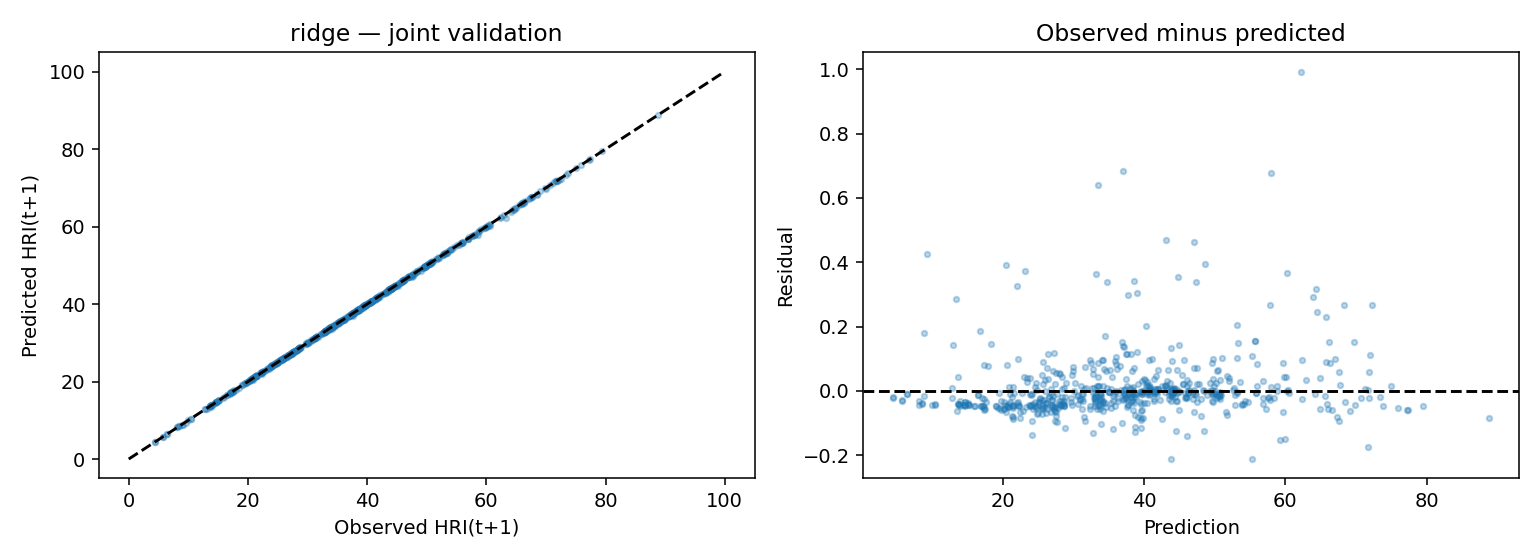

In [12]:
validation = views(frame)['joint']
y = validation[TARGET].to_numpy()
prediction = model.predict(validation[FEATURES])
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y, prediction, s=8, alpha=.3)
axes[0].plot([0, 100], [0, 100], 'k--')
axes[0].set(xlabel='Observed HRI(t+1)', ylabel='Predicted HRI(t+1)', title=MODEL_NAME + ' — joint validation')
axes[1].scatter(prediction, y-prediction, s=8, alpha=.3)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Prediction', ylabel='Residual', title='Observed minus predicted')
fig.tight_layout()
from io import BytesIO
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=140)
display(Image(data=image_buffer.getvalue()))
plt.close(fig)
